In [109]:
import pandas as pd
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [110]:
df = pd.read_csv("C:\\Users\\yunek\\OneDrive\\Desktop\\train.csv")
df.head(10)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,NaN,S
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,NaN,C


# Починаємо аналізувати та чистити дані

In [111]:
df.shape

(891, 12)

In [112]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [113]:
df['Age'].unique()

array([22.  , 38.  , 26.  , 35.  ,   nan, 54.  ,  2.  , 27.  , 14.  ,
        4.  , 58.  , 20.  , 39.  , 55.  , 31.  , 34.  , 15.  , 28.  ,
        8.  , 19.  , 40.  , 66.  , 42.  , 21.  , 18.  ,  3.  ,  7.  ,
       49.  , 29.  , 65.  , 28.5 ,  5.  , 11.  , 45.  , 17.  , 32.  ,
       16.  , 25.  ,  0.83, 30.  , 33.  , 23.  , 24.  , 46.  , 59.  ,
       71.  , 37.  , 47.  , 14.5 , 70.5 , 32.5 , 12.  ,  9.  , 36.5 ,
       51.  , 55.5 , 40.5 , 44.  ,  1.  , 61.  , 56.  , 50.  , 36.  ,
       45.5 , 20.5 , 62.  , 41.  , 52.  , 63.  , 23.5 ,  0.92, 43.  ,
       60.  , 10.  , 64.  , 13.  , 48.  ,  0.75, 53.  , 57.  , 80.  ,
       70.  , 24.5 ,  6.  ,  0.67, 30.5 ,  0.42, 34.5 , 74.  ])

In [114]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [115]:
# Створюємо колонку has_cabin, бо заповнити колонку Cabin нереально
df['Has_cabin'] = df['Cabin'].notnull()
df = df.drop(columns='Cabin')
df

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked,Has_cabin
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,S,False
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C,True
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,S,False
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,S,True
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,S,False
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,S,False
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,S,True
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,S,False
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C,True


In [116]:
# Заповнимо Embarked найпопулярнішим значенням
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])
df['Embarked'].isnull().sum()

0

In [117]:
df['Age'].value_counts()

Age
24.00    30
22.00    27
18.00    26
19.00    25
28.00    25
         ..
36.50     1
55.50     1
0.92      1
23.50     1
74.00     1
Name: count, Length: 88, dtype: int64

In [118]:
age_medians = df.groupby(['Pclass','Sex'])['Age'].median()
age_medians

Pclass  Sex   
1       female    35.0
        male      40.0
2       female    28.0
        male      30.0
3       female    21.5
        male      25.0
Name: Age, dtype: float64

In [119]:
# Заповнимо Age медіаною у відповідності до Pclass та Sex
def fill_age(row):
    if pd.isnull(row['Age']):
        return age_medians.loc[row['Pclass'], row['Sex']]
    else:
        return row['Age']

df['Age'] = df.apply(fill_age, axis=1)
df['Age'].isnull().sum()

0

In [120]:
df.isnull().sum()

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
Has_cabin      0
dtype: int64

In [121]:
df.head(40)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked,Has_cabin
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,S,False
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C,True
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,S,False
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,S,True
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,S,False
5,6,0,3,"Moran, Mr. James",male,25.0,0,0,330877,8.4583,Q,False
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,S,True
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,S,False
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,S,False
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,C,False


# Починаємо дадавати нові колонки

In [122]:
df['Family_Size'] = df['SibSp'] + df['Parch'] + 1 

df['Is_Alone'] = (df['Family_Size'] == 1).astype(int)

def age_group(age):
    if age < 10:
        return 'Child'
    elif age < 18:
        return 'Teen'
    elif age < 60:
        return 'Adult'
    else:
        return 'Old'
        
df['AgeGroup'] = df['Age'].apply(age_group)

df.loc[df['Family_Size'] == 1, 'FamilyCategory'] = 'Alone'
df.loc[(df['Family_Size'] > 1) & (df['Family_Size'] <= 3), 'FamilyCategory'] = 'Small'
df.loc[df['Family_Size'] > 3, 'FamilyCategory'] = 'Large'

df

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked,Has_cabin,Family_Size,Is_Alone,AgeGroup,FamilyCategory
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,S,False,2,0,Adult,Small
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C,True,2,0,Adult,Small
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,S,False,1,1,Adult,Alone
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,S,True,2,0,Adult,Small
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,S,False,1,1,Adult,Alone
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,S,False,1,1,Adult,Alone
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,S,True,1,1,Adult,Alone
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,21.5,1,2,W./C. 6607,23.4500,S,False,4,0,Adult,Large
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C,True,1,1,Adult,Alone


# Починаємо аналіз 

### Що сталося з дітьми безвідповідальних батьків?

In [123]:

Iron_child = df[(df['AgeGroup'] == 'Child') & (df['Is_Alone'] == 1)][['PassengerId', 'Name', 'Survived', 'Sex', 'Age']]
Iron_child

,PassengerId,Name,Survived,Sex,Age
777,778,"Emanuel, Miss. Virginia Ethel",1,female,5.0


### Ми знайшли самородок — п’ятирічну дівчинку, яка потрапила на Титанік без нікого й вижила.
### Перевіримо що саме зіграло більшу роль в її виживанні
### 1. її блатний ID 
### 2. її стать
### 3. її вік
### 4. те що вона була одна

# 1. Превіримо, чи дає перевагу блатний ID 

In [124]:
# список блатних індексів
good_ids = [111, 222, 333, 444, 555, 666, 777, 888]

# колонка: чи входить індекс у цей список
df['GoodID'] = df.index.isin(good_ids)
df['Lucky_ID'] = df['GoodID'].map({True: 'Lucky ID', False: 'Normal ID'})

# Змінюємо 0 та 1 на Died та Survived
df['Status'] = df['Survived'].map({0: 'Died', 1: 'Survived'})

survival_compare = (df.groupby(['Lucky_ID', 'Status']).size().reset_index(name='Count'))

survival_compare

,Lucky_ID,Status,Count
0,Lucky ID,Died,6
1,Lucky ID,Survived,2
2,Normal ID,Died,543
3,Normal ID,Survived,340


In [125]:
# Переводимо у відсотки
survival_compare['Percent'] = 100 * survival_compare['Count'] / survival_compare.groupby('Lucky_ID')['Count'].transform('sum')
survival_compare

,Lucky_ID,Status,Count,Percent
0,Lucky ID,Died,6,75.000000
1,Lucky ID,Survived,2,25.000000
2,Normal ID,Died,543,61.494904
3,Normal ID,Survived,340,38.505096


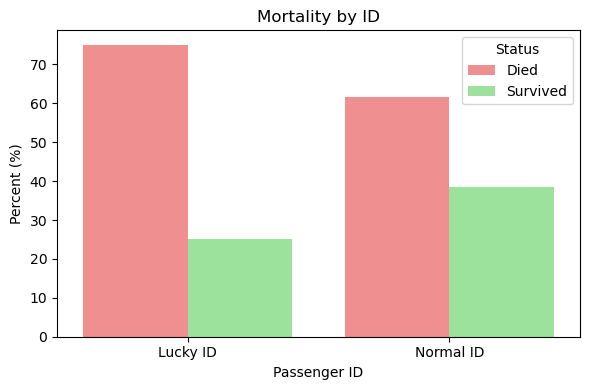

In [126]:
# Будуємо графік
plt.figure(figsize=(6,4))
sns.barplot(data=survival_compare,
    x='Lucky_ID',
    y='Percent',
    hue='Status',
    palette=['#ff7f7f', '#90ee90'] 
)

# Заголовки та підписи
plt.title('Mortality by ID')
plt.ylabel('Percent (%)')
plt.xlabel('Passenger ID')

plt.tight_layout()
plt.show()

# 2. Превіримо, чи дає перевагу стать

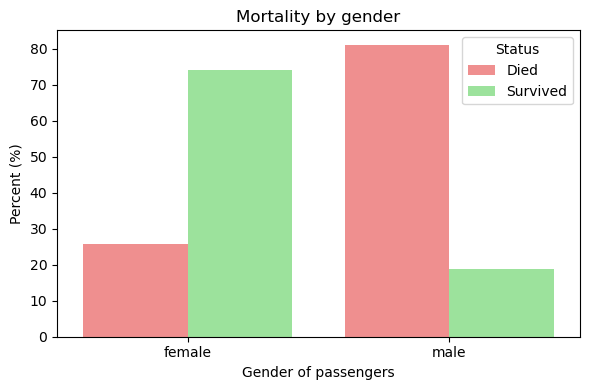

In [127]:
sex_survival = df.groupby(['Sex', 'Status']).size().reset_index(name='Count')
sex_survival['Percent'] = 100 * sex_survival['Count'] / sex_survival.groupby('Sex')['Count'].transform('sum')

plt.figure(figsize=(6,4))
sns.barplot(data=sex_survival,
    x='Sex',
    y='Percent',
    hue='Status',
    palette = ['#ff7f7f', '#90ee90']
)

plt.title('Mortality by gender')
plt.ylabel('Percent (%)')
plt.xlabel('Gender of passengers')

plt.tight_layout()
plt.show()

# 3. Превіримо, чи дає перевагу вік

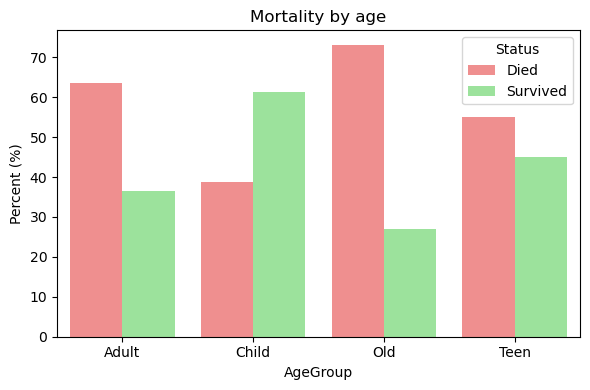

In [128]:
age_survival = df.groupby(['AgeGroup', 'Status']).size().reset_index(name='Count')
age_survival['Percent'] = 100 * age_survival['Count'] / age_survival.groupby('AgeGroup')['Count'].transform('sum')

plt.figure(figsize=(6,4))
sns.barplot(data=age_survival,
    x='AgeGroup',
    y='Percent',
    hue='Status',
    palette = ['#ff7f7f', '#90ee90'])

plt.title('Mortality by age')
plt.ylabel('Percent (%)')

plt.tight_layout()
plt.show()

In [133]:
df


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked,Has_cabin,Family_Size,Is_Alone,AgeGroup,FamilyCategory,GoodID,Lucky_ID,Status,AloneStatus
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,S,False,2,0,Adult,Small,False,Normal ID,Died,With someone
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C,True,2,0,Adult,Small,False,Normal ID,Survived,With someone
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,S,False,1,1,Adult,Alone,False,Normal ID,Survived,Alone
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,S,True,2,0,Adult,Small,False,Normal ID,Survived,With someone
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,S,False,1,1,Adult,Alone,False,Normal ID,Died,Alone
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,S,False,1,1,Adult,Alone,False,Normal ID,Died,Alone
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,S,True,1,1,Adult,Alone,False,Normal ID,Survived,Alone
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,21.5,1,2,W./C. 6607,23.4500,S,False,4,0,Adult,Large,True,Lucky ID,Died,With someone
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C,True,1,1,Adult,Alone,False,Normal ID,Survived,Alone


# 4. Превіримо, чи дає перевагу відлюдяність

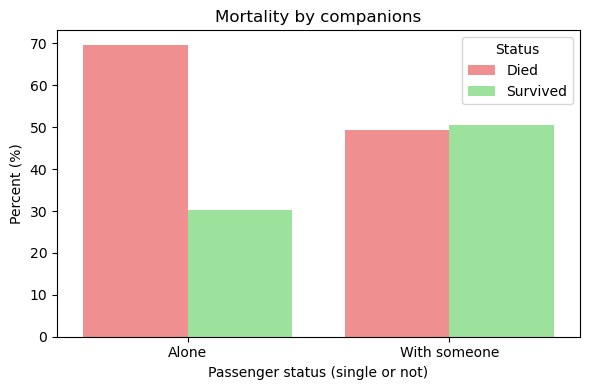

In [136]:
df['AloneStatus'] = df['Is_Alone'].map({1: 'Alone', 0: 'With someone'})

alone_survival = (df.groupby(['AloneStatus', 'Status']).size().reset_index(name='Count'))
alone_survival['Percent'] = (100 * alone_survival['Count'] /alone_survival.groupby('AloneStatus')['Count'].transform('sum'))

plt.figure(figsize=(6,4))
sns.barplot(data=alone_survival,
    x='AloneStatus',
    y='Percent',
    hue='Status',
    palette=['#ff7f7f', '#90ee90'])

plt.title('Mortality by companions')
plt.xlabel('Passenger status (single or not)')
plt.ylabel('Percent (%)')
plt.tight_layout()
plt.show()

# Висновок:
## 1. Пасажири з «блатним» номером квитка (ID у межах 111–888) мали вищу смертність, ніж решта пасажирів, але не суттєво.
## 2. Жінки виживали значно частіше, ніж чоловіки — їхня частка серед тих, хто врятувався, переважає.
## 3. За віковими групами лише серед дітей кількість тих, хто вижив, перевищує кількість загиблих.
## 4. Пасажири, які подорожували наодинці, мали набагато більшу смертність
## Отже, скоріш за все дівчинка вижила через свій вік, а стать, на мою думку, у випадку з п’ятирічною дитиною ролі не відіграє.

In [130]:
df


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked,Has_cabin,Family_Size,Is_Alone,AgeGroup,FamilyCategory,GoodID,Lucky_ID,Status,AloneStatus
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,S,False,2,0,Adult,Small,False,Normal ID,Died,With someone
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C,True,2,0,Adult,Small,False,Normal ID,Survived,With someone
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,S,False,1,1,Adult,Alone,False,Normal ID,Survived,Alone
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,S,True,2,0,Adult,Small,False,Normal ID,Survived,With someone
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,S,False,1,1,Adult,Alone,False,Normal ID,Died,Alone
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,S,False,1,1,Adult,Alone,False,Normal ID,Died,Alone
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,S,True,1,1,Adult,Alone,False,Normal ID,Survived,Alone
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,21.5,1,2,W./C. 6607,23.4500,S,False,4,0,Adult,Large,True,Lucky ID,Died,With someone
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C,True,1,1,Adult,Alone,False,Normal ID,Survived,Alone


In [131]:
new_df = df.drop(['PassengerId', 'Survived', 'SibSp', 'Parch', 'Is_Alone', 'GoodID'], axis=1)

new_df

,Pclass,Name,Sex,Age,Ticket,Fare,Embarked,Has_cabin,Family_Size,AgeGroup,FamilyCategory,Lucky_ID,Status,AloneStatus
0,3,"Braund, Mr. Owen Harris",male,22.0,A/5 21171,7.2500,S,False,2,Adult,Small,Normal ID,Died,With someone
1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,PC 17599,71.2833,C,True,2,Adult,Small,Normal ID,Survived,With someone
2,3,"Heikkinen, Miss. Laina",female,26.0,STON/O2. 3101282,7.9250,S,False,1,Adult,Alone,Normal ID,Survived,Alone
3,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,113803,53.1000,S,True,2,Adult,Small,Normal ID,Survived,With someone
4,3,"Allen, Mr. William Henry",male,35.0,373450,8.0500,S,False,1,Adult,Alone,Normal ID,Died,Alone
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,2,"Montvila, Rev. Juozas",male,27.0,211536,13.0000,S,False,1,Adult,Alone,Normal ID,Died,Alone
887,1,"Graham, Miss. Margaret Edith",female,19.0,112053,30.0000,S,True,1,Adult,Alone,Normal ID,Survived,Alone
888,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,21.5,W./C. 6607,23.4500,S,False,4,Adult,Large,Lucky ID,Died,With someone
889,1,"Behr, Mr. Karl Howell",male,26.0,111369,30.0000,C,True,1,Adult,Alone,Normal ID,Survived,Alone
